Importing necessary libraries

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt

import json
import pandas as pd
from ipywidgets import interact, IntSlider
from IPython.display import display, Markdown, Image

from pathlib import Path

import string
import re

Play with 510.csv data

In [2]:
file_path_510 = Path(r"C:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\newyorker_caption_contest\data\510.csv")

df = pd.read_csv(file_path_510)

# Show first 5 rows
print("First 5 rows:")
print(df.head())

First 5 rows:
   rank                                            caption      mean  \
0     0          I'm a congressman--obstruction is my job.  1.913043   
1     1  I'm what they mean when they say, 'The middle ...  1.842105   
2     2                  Does this suit make me look flat?  1.711111   
3     3    When the right woman comes along, I'll know it.  1.625000   
4     4  I used to lie in the gutter, but then I quit d...  1.617647   

   precision  votes  not_funny  somewhat_funny  funny  
0   0.094022     69         24              27     18  
1   0.191381     19          8               6      5  
2   0.112915     45         21              16      8  
3   0.116657     32         15              14      3  
4   0.133610     34         19               9      6  


Clean the text to analyse it better:

In [3]:
df["caption"] = df["caption"].str.replace(r"[--]", " ", regex=True)
df["caption"] = df["caption"].str.replace(r"[.,?]", " ", regex=True)

# Save the cleaned version
df.to_csv("cleaned_file.csv", index=False)

print(df["caption"].head())


0            I'm a congressman  obstruction is my job 
1    I'm what they mean when they say  'The middle ...
2                    Does this suit make me look flat 
3      When the right woman comes along  I'll know it 
4    I used to lie in the gutter  but then I quit d...
Name: caption, dtype: object


In [4]:
# get rid of unnecessary punctuation and turn everything to lower case
df["caption"] = (
    df["caption"]
    .astype(str)                                 # ensure strings, preserves NaN as "nan" if needed
    .str.replace(r"[—–-]+", " ", regex=True)     # replace em/en/ASCII hyphens (one or more) with a space
    .str.replace(r"[.,?]", "", regex=True)       # remove commas, periods and question marks
    .str.lower()                                 # lowercase
    .str.replace(r"\s+", " ", regex=True)        # collapse multiple spaces
    .str.strip()                                 # trim edges
)

print(df["caption"].tolist()) # check if it works


["i'm a congressman obstruction is my job", "i'm what they mean when they say 'the middle class is getting stepped on '", 'does this suit make me look flat', "when the right woman comes along i'll know it", 'i used to lie in the gutter but then i quit drinking', 'if you can meditate here you can meditate anywhere', 'sorry for the inconvenience i probably should have jumped from a higher window', "i've decided to take it lying down", 'anyone who steps on me is out!', 'guess i should have jumped from a few floors higher', 'my life has become so pedestrian', 'i may have misinterpreted one of the twelve steps', 'i should have jumped from a higher floor', "i'm doing a study on the indifference of man so far you're all doing great!", "walk around i'm occupying wall street", "i'm waiting for the chalk guy", 'you probably know my column: man on the street', 'will move for food', 'my therapist is right i do let everyone walk all over me', "it's the only place that i don't get stepped on", 'brot

In [5]:
import sys
print(sys.executable)

!{sys.executable} -m pip install contractions

c:\Users\mered\anaconda3\python.exe


In [6]:
# handle contractions -> for this do "pip install contractions"

import contractions 

df["caption"] = df["caption"].apply(lambda x: contractions.fix(x))   

print(df["caption"].tolist()) # check if it works

['i am a congressman obstruction is my job', "i am what they mean when they say 'the middle class is getting stepped on '", 'does this suit make me look flat', 'when the right woman comes along i will know it', 'i used to lie in the gutter but then i quit drinking', 'if you can meditate here you can meditate anywhere', 'sorry for the inconvenience i probably should have jumped from a higher window', 'i have decided to take it lying down', 'anyone who steps on me is out!', 'guess i should have jumped from a few floors higher', 'my life has become so pedestrian', 'i may have misinterpreted one of the twelve steps', 'i should have jumped from a higher floor', 'i am doing a study on the indifference of man so far you are all doing great!', 'walk around i am occupying wall street', 'i am waiting for the chalk guy', 'you probably know my column: man on the street', 'will move for food', 'my therapist is right i do let everyone walk all over me', 'it is the only place that i do not get steppe

Count the number of words in each line and look if there is a correlation between length and score 

In [7]:
# words per line
df["word_counts"] = [len(line.split()) for line in df["caption"]]
print(df["word_counts"])

# characters per line
df["length"] = [len(line) for line in df["caption"]]

# average length in this csv file (501) 
print("Basic statistics:")
print(f"Average word count: {df['word_counts'].mean():.2f}")
print(f"Average character count: {df['length'].mean():.2f}")
print(f"Dataset size: {len(df)} captions")


0        8
1       16
2        7
3       10
4       12
        ..
3900    12
3901     9
3902     8
3903     8
3904     6
Name: word_counts, Length: 3905, dtype: int64
Basic statistics:
Average word count: 9.85
Average character count: 48.68
Dataset size: 3905 captions


In [8]:
# import libraries for data plotting and analysis
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# plotting style
plt.style.use('default')
sns.set_palette("husl")

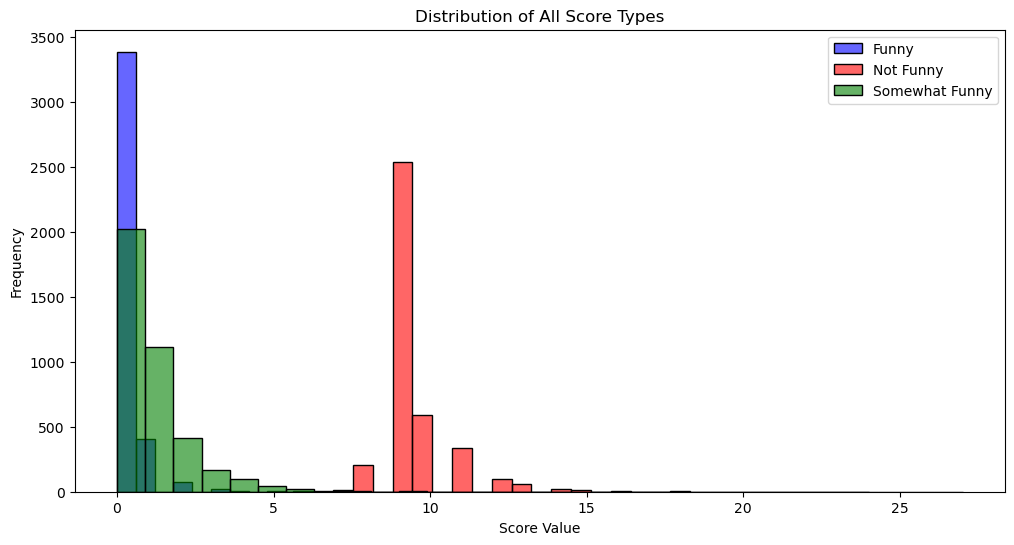

In [9]:
# scores
df['all_votes'] = df['not_funny'] + df['funny'] + df['somewhat_funny']

# check score distribution

plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='funny', bins=30, alpha=0.6, label='Funny', color='blue')
sns.histplot(data=df, x='not_funny', bins=30, alpha=0.6, label='Not Funny', color='red')
sns.histplot(data=df, x='somewhat_funny', bins=30, alpha=0.6, label='Somewhat Funny', color='green')
plt.title('Distribution of All Score Types')
plt.xlabel('Score Value')
plt.ylabel('Frequency')
plt.legend()
plt.show()




In [10]:
# total votes for each caption
df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny']

# proportions for each category
df['prop_not_funny'] = df['not_funny'] / df['total_votes']
df['prop_somewhat_funny'] = df['somewhat_funny'] / df['total_votes']
df['prop_funny'] = df['funny'] / df['total_votes']

print(f"\nVote summary:")
print(f"Total votes across all captions: {df['total_votes'].sum()}")
print(f"Average votes per caption: {df['total_votes'].mean():.1f}")

# create a Composite "Funny Score"

# weighted average (funny=2, somewhat_funny=1, not_funny=0)
df['funny_score_weighted'] = (df['funny'] * 2 + df['somewhat_funny'] * 1 + df['not_funny'] * 0) / df['total_votes']

df['success_metric'] = df['funny_score_weighted']

print(f"\nSuccess metric range: {df['success_metric'].min():.3f} to {df['success_metric'].max():.3f}")




Vote summary:
Total votes across all captions: 41185
Average votes per caption: 10.5

Success metric range: 0.000 to 0.913


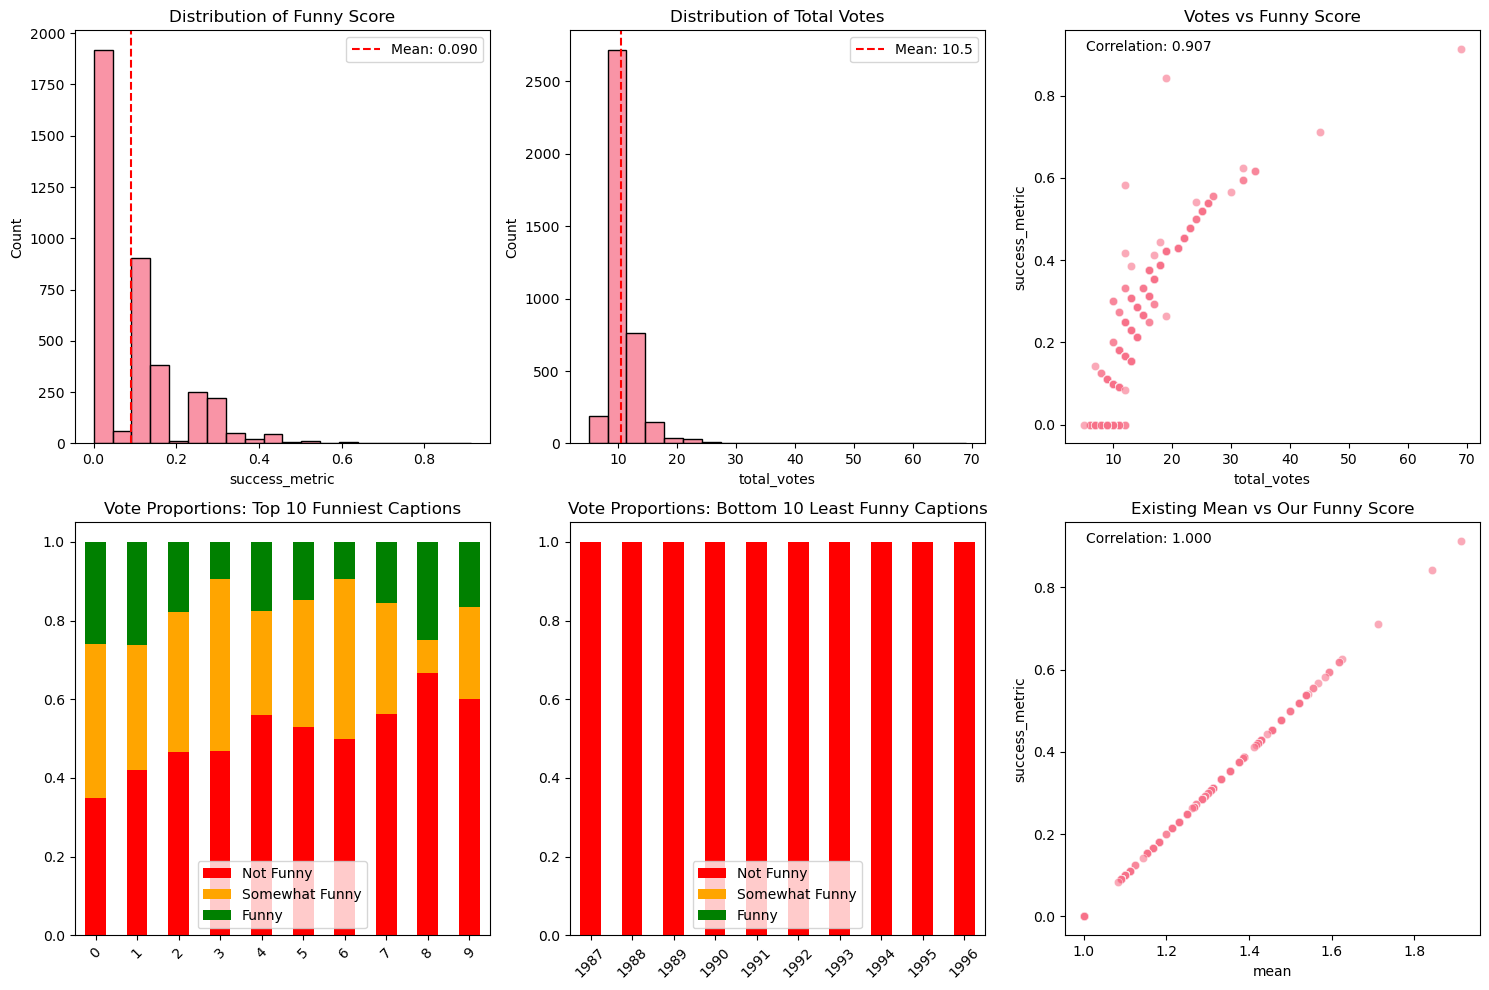

In [11]:
# distribution Analysis

plt.figure(figsize=(15, 10))

    # distribution of success metric
plt.subplot(2, 3, 1)
sns.histplot(data=df, x='success_metric', bins=20)
plt.title('Distribution of Funny Score')
plt.axvline(df['success_metric'].mean(), color='red', linestyle='--', label=f"Mean: {df['success_metric'].mean():.3f}")
plt.legend()

    # vote distribution
plt.subplot(2, 3, 2)
sns.histplot(data=df, x='total_votes', bins=20)
plt.title('Distribution of Total Votes')
plt.axvline(df['total_votes'].mean(), color='red', linestyle='--', label=f"Mean: {df['total_votes'].mean():.1f}")
plt.legend()

    # correlation between votes and success
plt.subplot(2, 3, 3)
sns.scatterplot(data=df, x='total_votes', y='success_metric', alpha=0.6)
plt.title('Votes vs Funny Score')
corr_votes = df['total_votes'].corr(df['success_metric'])
plt.text(0.05, 0.95, f'Correlation: {corr_votes:.3f}', transform=plt.gca().transAxes)

    # proportion breakdown for top captions
plt.subplot(2, 3, 4)
top_10 = df.nlargest(10, 'success_metric')[['prop_not_funny', 'prop_somewhat_funny', 'prop_funny']]
top_10.plot(kind='bar', stacked=True, ax=plt.gca(), 
            color=['red', 'orange', 'green'])
plt.title('Vote Proportions: Top 10 Funniest Captions')
plt.xticks(rotation=45)
plt.legend(['Not Funny', 'Somewhat Funny', 'Funny'])

    # proportion breakdown for bottom captions
plt.subplot(2, 3, 5)
bottom_10 = df.nsmallest(10, 'success_metric')[['prop_not_funny', 'prop_somewhat_funny', 'prop_funny']]
bottom_10.plot(kind='bar', stacked=True, ax=plt.gca(), 
               color=['red', 'orange', 'green'])
plt.title('Vote Proportions: Bottom 10 Least Funny Captions')
plt.xticks(rotation=45)
plt.legend(['Not Funny', 'Somewhat Funny', 'Funny'])

    # relationship between existing 'mean' and our new score
plt.subplot(2, 3, 6)
sns.scatterplot(data=df, x='mean', y='success_metric', alpha=0.6)
plt.title('Existing Mean vs Our Funny Score')
corr_mean = df['mean'].corr(df['success_metric'])
plt.text(0.05, 0.95, f'Correlation: {corr_mean:.3f}', transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()



Correlation with Funny Score:
Word count correlation: -0.069 (p-value: 0.000)
Character count correlation: -0.075 (p-value: 0.000)


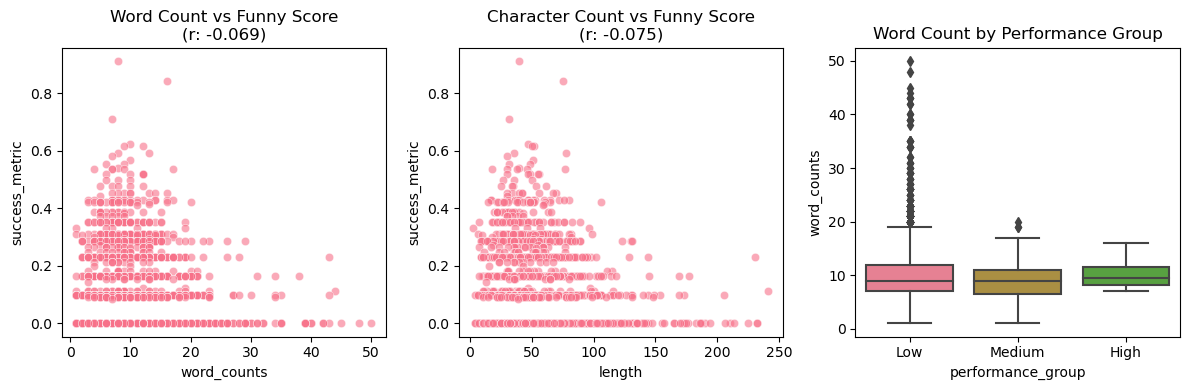

In [15]:

# text Analysis with Proper Success Metric
    # Correlation analysis
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
corr_char_score, p_char = pearsonr(df['length'], df['success_metric'])

print(f"\nCorrelation with Funny Score:")
print(f"Word count correlation: {corr_word_score:.3f} (p-value: {p_word:.3f})")
print(f"Character count correlation: {corr_char_score:.3f} (p-value: {p_char:.3f})")

# Visualization
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='word_counts', y='success_metric', alpha=0.6)
plt.title(f'Word Count vs Funny Score\n(r: {corr_word_score:.3f})')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df, x='length', y='success_metric', alpha=0.6)
plt.title(f'Character Count vs Funny Score\n(r: {corr_char_score:.3f})')

plt.subplot(1, 3, 3)
# Create performance groups for comparison
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])

sns.boxplot(data=df, x='performance_group', y='word_counts')
plt.title('Word Count by Performance Group')

plt.tight_layout()
plt.show()


In [17]:

# compare Top vs Bottom Performers
from scipy.stats import ttest_ind 

# Define top and bottom performers (e.g., top 20% vs bottom 20%)
top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nPerformance Comparison:")
print(f"Top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"Bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

# Compare metrics
print(f"\nWord count comparison:")
print(f"Top performers: {top_captions['word_counts'].mean():.1f} ± {top_captions['word_counts'].std():.1f}")
print(f"Bottom performers: {bottom_captions['word_counts'].mean():.1f} ± {bottom_captions['word_counts'].std():.1f}")

# Statistical test
t_stat, p_val = ttest_ind(top_captions['word_counts'], bottom_captions['word_counts'])
print(f"T-test p-value: {p_val:.4f}")




Performance Comparison:
Top 20% cutoff: 0.167 (1011 captions)
Bottom 20% cutoff: 0.000 (1918 captions)

Word count comparison:
Top performers: 9.3 ± 4.4
Bottom performers: 10.2 ± 5.5
T-test p-value: 0.0000


In [18]:
# examples

print("\n" + "="*60)
print("EXAMPLE CAPTIONS")
print("="*60)

print("\nTOP 5 FUNNIEST CAPTIONS:")
top_5 = df.nlargest(5, 'success_metric')[['caption', 'success_metric', 'funny', 'somewhat_funny', 'not_funny']]
for idx, row in top_5.iterrows():
    print(f"\nScore: {row['success_metric']:.3f} (Funny: {row['funny']}, Somewhat: {row['somewhat_funny']}, Not: {row['not_funny']})")
    print(f"Caption: {row['caption']}")

print("\nBOTTOM 5 LEAST FUNNY CAPTIONS:")
bottom_5 = df.nsmallest(5, 'success_metric')[['caption', 'success_metric', 'funny', 'somewhat_funny', 'not_funny']]
for idx, row in bottom_5.iterrows():
    print(f"\nScore: {row['success_metric']:.3f} (Funny: {row['funny']}, Somewhat: {row['somewhat_funny']}, Not: {row['not_funny']})")
    print(f"Caption: {row['caption']}")


# quick Sentiment Analysis

#  check on top vs bottom

import nltk
from nltk.sentiment import SentimentIntensityAnalyzer as sia

def quick_sentiment(text):
    return sia.polarity_scores(text)['compound']

top_captions['sentiment'] = top_captions['caption'].apply(quick_sentiment)
bottom_captions['sentiment'] = bottom_captions['caption'].apply(quick_sentiment)

print(f"\nSentiment Comparison:")
print(f"Top performers sentiment: {top_captions['sentiment'].mean():.3f}")
print(f"Bottom performers sentiment: {bottom_captions['sentiment'].mean():.3f}")

sentiment_t, sentiment_p = ttest_ind(top_captions['sentiment'], bottom_captions['sentiment'])
print(f"Sentiment t-test p-value: {sentiment_p:.4f}")


EXAMPLE CAPTIONS

TOP 5 FUNNIEST CAPTIONS:

Score: 0.913 (Funny: 18, Somewhat: 27, Not: 24)
Caption: i am a congressman obstruction is my job

Score: 0.842 (Funny: 5, Somewhat: 6, Not: 8)
Caption: i am what they mean when they say 'the middle class is getting stepped on '

Score: 0.711 (Funny: 8, Somewhat: 16, Not: 21)
Caption: does this suit make me look flat

Score: 0.625 (Funny: 3, Somewhat: 14, Not: 15)
Caption: when the right woman comes along i will know it

Score: 0.618 (Funny: 6, Somewhat: 9, Not: 19)
Caption: i used to lie in the gutter but then i quit drinking

BOTTOM 5 LEAST FUNNY CAPTIONS:

Score: 0.000 (Funny: 0, Somewhat: 0, Not: 9)
Caption: that is right just walk all over me you would not be the first

Score: 0.000 (Funny: 0, Somewhat: 0, Not: 10)
Caption: lost my job now my dignity

Score: 0.000 (Funny: 0, Somewhat: 0, Not: 9)
Caption: if i am going to get walked all over it is going to be on *my* terms ["my" in italics]

Score: 0.000 (Funny: 0, Somewhat: 0, Not: 9)
C

TypeError: SentimentIntensityAnalyzer.polarity_scores() missing 1 required positional argument: 'text'

Now lets see if some words correlate with higher scores


In [19]:
from collections import Counter

# first, lets get rid of common words such as "a, the, an, he, she, I..." so that we don't cound them in (these are considered stop words)

from nltk.corpus import stopwords
import nltk

# Download NLTK stopwords (run once)
nltk.download('stopwords')

def get_stopword_lists():
    """Get different stop word lists for different use cases"""
    
    # English stop words
    basic_stopwords = set(stopwords.words('english'))
    
    # Extended stop words - add custom words
    extended_stopwords = basic_stopwords.union({
        'like', 'get', 'would', 'could', 'also', 'us', 'one', 'two', 'three'
    })
    
    # Sentiment-safe stop words (keep negation words)
    sentiment_safe_stopwords = basic_stopwords - {
        'not', 'no', 'nor', 'never', 'none', 'neither', 'do not',  
        'are not', 'could not', 'did not',
        'does not', 'had not', 'has not', 'have not', 'is not', 'might not', 'must not',
        'need not', 'shall not', 'should not', 
        'was not', 'were not', 'will not', 'would not'
    }
    
    return {
        'basic': basic_stopwords,
        'extended': extended_stopwords,
        'sentiment_safe': sentiment_safe_stopwords,
        'custom': set()  # Empty set for no stopword removal
    }

def analyze_with_stopwords(df, caption_column='caption', stopword_type='basic', top_n=20):
    """Analyze word frequency with different stopword options"""
    
    stopword_lists = get_stopword_lists()
    selected_stopwords = stopword_lists[stopword_type]
    
    # Combine all captions
    all_text = ' '.join(df[caption_column].dropna().astype(str))
    
    # Clean and tokenize
    words = re.findall(r'\b[a-zA-Z]+\b', all_text.lower())
    
    # Remove selected stopwords
    if selected_stopwords:
        words = [word for word in words if word not in selected_stopwords]
    
    # Count frequencies
    word_freq = Counter(words)
    
    return pd.DataFrame(word_freq.most_common(top_n), 
                       columns=['word', 'frequency'])

# Usage examples
print("=== BASIC STOPWORDS REMOVED ===")
basic_results = analyze_with_stopwords(df, 'caption', 'basic', 10)
print(basic_results)

print("\n=== SENTIMENT-SAFE STOPWORDS ===")
sentiment_results = analyze_with_stopwords(df, 'caption', 'sentiment_safe', 10)
print(sentiment_results)

print("\n=== NO STOPWORDS REMOVED ===")
no_stopwords_results = analyze_with_stopwords(df, 'caption', 'custom', 10)
print(no_stopwords_results)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mered\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


=== BASIC STOPWORDS REMOVED ===
     word  frequency
0    like        264
1  people        227
2    walk        178
3     new        172
4     get        153
5     one        142
6   would        133
7  street        127
8    life        108
9    look        105

=== SENTIMENT-SAFE STOPWORDS ===
     word  frequency
0     not        519
1    like        264
2  people        227
3    walk        178
4     new        172
5     get        153
6     one        142
7   would        133
8  street        127
9    life        108

=== NO STOPWORDS REMOVED ===
  word  frequency
0    i       1976
1  the       1378
2    a       1042
3   to        958
4   is        827
5   my        662
6   am        661
7  you        623
8   it        553
9   me        538


In [20]:
def get_most_common_words(text_series, n=30, remove_stopwords=True):
    # Combine all captions into one text
    all_text = ' '.join(text_series.dropna().astype(str))
    
    # Clean and tokenize text
    words = re.findall(r'\b[a-zA-Z]+\b', all_text.lower())
    
    # Remove stopwords (optional)
    if remove_stopwords:
        from nltk.corpus import stopwords
        import nltk
        nltk.download('stopwords')
        stop_words = set(stopwords.words('english'))
        words = [word for word in words if word not in stop_words]
    
    # Count word frequencies
    word_counts = Counter(words)
    return word_counts.most_common(n)

# Usage
most_common = get_most_common_words(df['caption'], n=20)
print("Most common words:")
for word, count in most_common:
    print(f"{word}: {count}")

Most common words:
like: 264
people: 227
walk: 178
new: 172
get: 153
one: 142
would: 133
street: 127
life: 108
look: 105
said: 105
see: 104
step: 97
back: 93
right: 86
let: 83
looks: 83
sidewalk: 81
think: 79
know: 78


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mered\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Analysis of vocabulary richness using TTR (type-token ratio) aka # of unique words / total words
Then we will analyse whether winning prompts use a more diverse vocabulary or not

In [22]:
from collections import Counter
from scipy.stats import ttest_ind, pearsonr

In [28]:
# calculation of vocabulary richness metrics
def calculate_vocabulary_richness(text_series, remove_stopwords=True):
    """
    calculation of vocabulary richness metrics for a series of texts
    Returns: dataFrame w/ TTR, unique_words, total_words for each caption
    """
    results = []
    
    stop_words = set()
    if remove_stopwords:
        from nltk.corpus import stopwords
        stop_words = set(stopwords.words('english'))
    
    for caption in text_series:
        if pd.isna(caption) or caption == '':
            results.append({'ttr': 0, 'unique_words': 0, 'total_words': 0})
            continue
            
        # Clean and tokenize
        words = re.findall(r'\b[a-zA-Z]+\b', caption.lower())
        
        # Remove stopwords
        if remove_stopwords:
            words = [word for word in words if word not in stop_words]
        
        if len(words) == 0:
            results.append({'ttr': 0, 'unique_words': 0, 'total_words': 0})
            continue
            
        # Calculate metrics
        unique_words = len(set(words))
        total_words = len(words)
        ttr = unique_words / total_words if total_words > 0 else 0
        
        results.append({
            'ttr': ttr,
            'unique_words': unique_words,
            'total_words': total_words
        })
    
    return pd.DataFrame(results)

# check if we already have these columns & remove them if they exist 
columns_to_remove = ['ttr', 'unique_words', 'total_words']
existing_cols = [col for col in columns_to_remove if col in df.columns]
if existing_cols:
    df = df.drop(columns=existing_cols)
    print(f"Removed existing columns: {existing_cols}")

# calculate vocab richness for all captions
vocab_metrics = calculate_vocabulary_richness(df['caption'], remove_stopwords=True)

# check for duplicate columns before merging 
print("Vocabulary metrics columns:", vocab_metrics.columns.tolist())
print("Vocabulary metrics shape:", vocab_metrics.shape)

# Add the new columns to the main DataFrame
df = pd.concat([df, vocab_metrics], axis=1)

print("Vocabulary metrics calculated and added to DataFrame")
print("New DataFrame columns:", df.columns.tolist())


Removed existing columns: ['ttr', 'unique_words', 'total_words']
Vocabulary metrics columns: ['ttr', 'unique_words', 'total_words']
Vocabulary metrics shape: (3905, 3)
Vocabulary metrics calculated and added to DataFrame
New DataFrame columns: ['rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny', 'funny', 'word_counts', 'length', 'all_votes', 'total_votes', 'prop_not_funny', 'prop_somewhat_funny', 'prop_funny', 'funny_score_weighted', 'success_metric', 'performance_group', 'ttr', 'unique_words', 'total_words']


In [29]:
# basics stats 

print(f"Average TTR: {df['ttr'].mean():.3f}")
print(f"Average unique words per caption: {df['unique_words'].mean():.1f}")
print(f"Average total words per caption: {df['total_words'].mean():.1f}")
print(f"Dataset size: {len(df)} captions")

Average TTR: 0.979
Average unique words per caption: 4.7
Average total words per caption: 4.8
Dataset size: 3905 captions


In [30]:
# comparison of top vs bottom performance 

top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\n=== PERFORMANCE GROUPS ===")
print(f"Top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"Bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

print(f"\n=== VOCABULARY RICHNESS COMPARISON ===")
print("Top performers:")
print(f"  TTR: {top_captions['ttr'].mean():.3f} ± {top_captions['ttr'].std():.3f}")
print(f"  Unique words: {top_captions['unique_words'].mean():.1f} ± {top_captions['unique_words'].std():.1f}")
print(f"  Total words: {top_captions['total_words'].mean():.1f} ± {top_captions['total_words'].std():.1f}")

print("\nBottom performers:")
print(f"  TTR: {bottom_captions['ttr'].mean():.3f} ± {bottom_captions['ttr'].std():.3f}")
print(f"  Unique words: {bottom_captions['unique_words'].mean():.1f} ± {bottom_captions['unique_words'].std():.1f}")
print(f"  Total words: {bottom_captions['total_words'].mean():.1f} ± {bottom_captions['total_words'].std():.1f}")


=== PERFORMANCE GROUPS ===
Top 20% cutoff: 0.167 (1011 captions)
Bottom 20% cutoff: 0.000 (1918 captions)

=== VOCABULARY RICHNESS COMPARISON ===
Top performers:
  TTR: 0.984 ± 0.084
  Unique words: 4.4 ± 2.1
  Total words: 4.5 ± 2.1

Bottom performers:
  TTR: 0.975 ± 0.100
  Unique words: 4.8 ± 2.6
  Total words: 5.0 ± 2.8


In [31]:
# stat test 

t_stat_ttr, p_val_ttr = ttest_ind(top_captions['ttr'], bottom_captions['ttr'])
t_stat_unique, p_val_unique = ttest_ind(top_captions['unique_words'], bottom_captions['unique_words'])
t_stat_total, p_val_total = ttest_ind(top_captions['total_words'], bottom_captions['total_words'])

print(f"\n=== STATISTICAL SIGNIFICANCE (T-TESTS) ===")
print(f"TTR: p-value = {p_val_ttr:.4f} {'***' if p_val_ttr < 0.001 else '**' if p_val_ttr < 0.01 else '*' if p_val_ttr < 0.05 else 'ns'}")
print(f"Unique words: p-value = {p_val_unique:.4f} {'***' if p_val_unique < 0.001 else '**' if p_val_unique < 0.01 else '*' if p_val_unique < 0.05 else 'ns'}")
print(f"Total words: p-value = {p_val_total:.4f} {'***' if p_val_total < 0.001 else '**' if p_val_total < 0.01 else '*' if p_val_total < 0.05 else 'ns'}")


=== STATISTICAL SIGNIFICANCE (T-TESTS) ===
TTR: p-value = 0.0202 *
Unique words: p-value = 0.0000 ***
Total words: p-value = 0.0000 ***


In [32]:
# correlation analsys

corr_ttr, p_corr_ttr = pearsonr(df['ttr'], df['success_metric'])
corr_unique, p_corr_unique = pearsonr(df['unique_words'], df['success_metric'])
corr_total, p_corr_total = pearsonr(df['total_words'], df['success_metric'])

print(f"\n=== CORRELATION WITH SUCCESS METRIC ===")
print(f"TTR correlation: {corr_ttr:.3f} (p-value: {p_corr_ttr:.4f})")
print(f"Unique words correlation: {corr_unique:.3f} (p-value: {p_corr_unique:.4f})")
print(f"Total words correlation: {corr_total:.3f} (p-value: {p_corr_total:.4f})")



=== CORRELATION WITH SUCCESS METRIC ===
TTR correlation: 0.030 (p-value: 0.0614)
Unique words correlation: -0.073 (p-value: 0.0000)
Total words correlation: -0.081 (p-value: 0.0000)


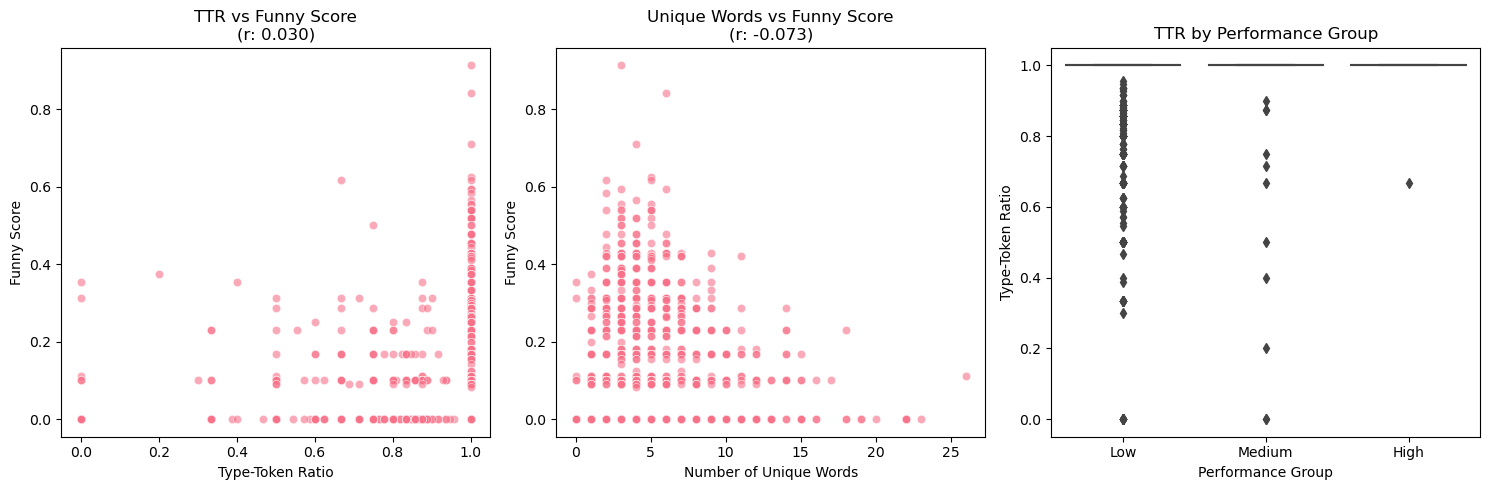

In [33]:
# plotting 

plt.figure(figsize=(15, 5))

# TTR vs Success Metric
plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='ttr', y='success_metric', alpha=0.6)
plt.title(f'TTR vs Funny Score\n(r: {corr_ttr:.3f})')
plt.xlabel('Type-Token Ratio')
plt.ylabel('Funny Score')

# Unique words vs Success Metric
plt.subplot(1, 3, 2)
sns.scatterplot(data=df, x='unique_words', y='success_metric', alpha=0.6)
plt.title(f'Unique Words vs Funny Score\n(r: {corr_unique:.3f})')
plt.xlabel('Number of Unique Words')
plt.ylabel('Funny Score')

# Boxplot of TTR by performance group
plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='performance_group', y='ttr')
plt.title('TTR by Performance Group')
plt.xlabel('Performance Group')
plt.ylabel('Type-Token Ratio')

plt.tight_layout()
plt.show()

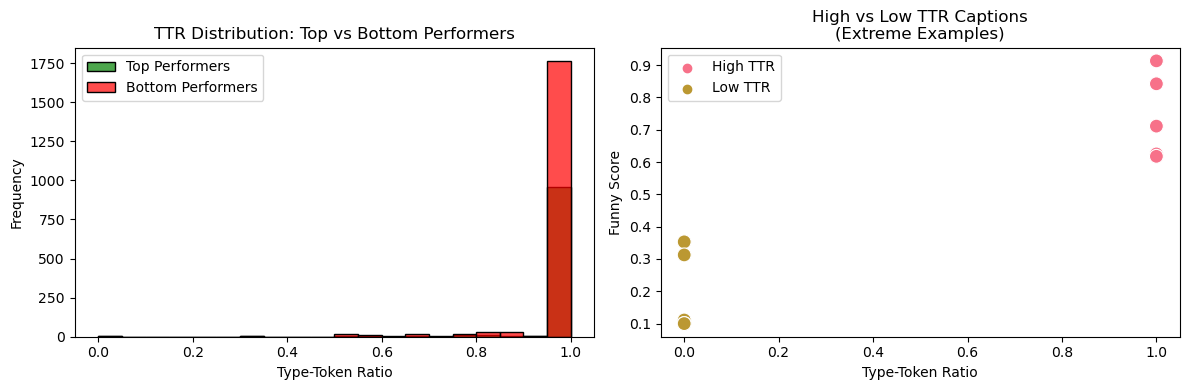

In [34]:
# Additional analysis: TTR distribution by performance
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(data=top_captions, x='ttr', bins=20, alpha=0.7, label='Top Performers', color='green')
sns.histplot(data=bottom_captions, x='ttr', bins=20, alpha=0.7, label='Bottom Performers', color='red')
plt.title('TTR Distribution: Top vs Bottom Performers')
plt.xlabel('Type-Token Ratio')
plt.ylabel('Frequency')
plt.legend()

plt.subplot(1, 2, 2)
# Show examples of high and low TTR captions
high_ttr_captions = df.nlargest(5, 'ttr')[['caption', 'ttr', 'success_metric']]
low_ttr_captions = df.nsmallest(5, 'ttr')[['caption', 'ttr', 'success_metric']]

# Create a table for the plot
examples_df = pd.concat([
    high_ttr_captions.assign(type='High TTR'),
    low_ttr_captions.assign(type='Low TTR')
])

sns.scatterplot(data=examples_df, x='ttr', y='success_metric', hue='type', s=100)
plt.title('High vs Low TTR Captions\n(Extreme Examples)')
plt.xlabel('Type-Token Ratio')
plt.ylabel('Funny Score')
plt.legend()

plt.tight_layout()
plt.show()

check résultats parce que ça a l'air chelou

In [36]:
print("=== REALISTIC INTERPRETATION OF RESULTS ===")

print("\n📊 ACTUAL FINDINGS:")
print("1. TTR DIFFERENCE IS MINIMAL: 0.984 vs 0.975 = 0.009 difference")
print("2. This is only a 0.9% relative difference - practically insignificant")
print("3. The statistical significance (p=0.02) comes from large sample size, not meaningful effect")

print(f"\n🔍 PRACTICAL SIGNIFICANCE VS STATISTICAL SIGNIFICANCE:")
print(f"• TTR difference: {0.984 - 0.975:.3f} (tiny absolute difference)")
print(f"• Statistical significance: p = 0.020 (significant due to n=2929)")
print(f"• Effect size: {(0.984-0.975)/df['ttr'].std():.3f} standard deviations (very small)")

# Calculate Cohen's d for effect size
from scipy.stats import ttest_ind
t_stat, p_val = ttest_ind(top_captions['ttr'], bottom_captions['ttr'])
cohens_d = (top_captions['ttr'].mean() - bottom_captions['ttr'].mean()) / ((top_captions['ttr'].std() + bottom_captions['ttr'].std()) / 2)

print(f"• Cohen's d: {cohens_d:.3f} (negligible effect size)")

print(f"\n💡 KEY INSIGHT:")
print("The TTR 'difference' is statistically significant (is the effect real of random noise?) but PRACTICALLY MEANINGLESS (is this effect large enough to actually matter in here? " \
")")
print("Both groups have extremely high TTR (>0.97), meaning nearly all words are unique")

=== REALISTIC INTERPRETATION OF RESULTS ===

📊 ACTUAL FINDINGS:
1. TTR DIFFERENCE IS MINIMAL: 0.984 vs 0.975 = 0.009 difference
2. This is only a 0.9% relative difference - practically insignificant
3. The statistical significance (p=0.02) comes from large sample size, not meaningful effect

🔍 PRACTICAL SIGNIFICANCE VS STATISTICAL SIGNIFICANCE:
• TTR difference: 0.009 (tiny absolute difference)
• Statistical significance: p = 0.020 (significant due to n=2929)
• Effect size: 0.095 standard deviations (very small)
• Cohen's d: 0.093 (negligible effect size)

💡 KEY INSIGHT:
The TTR 'difference' is statistically significant (is the effect real of random noise?) but PRACTICALLY MEANINGLESS (is this effect large enough to actually matter in here? )
Both groups have extremely high TTR (>0.97), meaning nearly all words are unique


-> THIS CONCLUSION MIGHT CHANGE IF WE LOOK AT ALL THE DATE AND NOT JUST ONE CSV

Lets compare now the caption description w/ the prompt & see if prompts that explain a little/give info on caption work better/have higher scores? 

In [37]:
# libraries for descriptveness analysis 

import nltk
from sklearn.feature_extraction.text import TfidfVectorizer


# required NLTK data
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\mered\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\mered\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger.zip.


True

In [38]:
def calculate_descriptiveness_metrics(caption):
    """
    Calculate multiple metrics to estimate how descriptive a caption is
    """
    if pd.isna(caption) or caption == '':
        return {
            'descriptive_word_ratio': 0,
            'noun_ratio': 0,
            'concreteness_score': 0,
            'question_indicator': 0,
            'exclamation_indicator': 0
        }
    
    words = nltk.word_tokenize(str(caption).lower())
    pos_tags = nltk.pos_tag(words)
    
    # Metric 1: Ratio of descriptive words (nouns, adjectives, verbs)
    descriptive_pos = ['NN', 'NNS', 'JJ', 'JJR', 'JJS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ']
    descriptive_words = [word for word, pos in pos_tags if pos in descriptive_pos]
    descriptive_ratio = len(descriptive_words) / len(words) if words else 0
    
    # Metric 2: Noun ratio specifically
    nouns = [word for word, pos in pos_tags if pos in ['NN', 'NNS']]
    noun_ratio = len(nouns) / len(words) if words else 0
    
    # Metric 3: Simple concreteness proxy (common concrete nouns)
    concrete_nouns = {'man', 'woman', 'person', 'people', 'dog', 'cat', 'car', 'house', 
                     'room', 'table', 'chair', 'book', 'phone', 'computer', 'window',
                     'door', 'tree', 'street', 'city', 'water', 'food', 'child', 'bird'}
    concrete_count = len([word for word in words if word in concrete_nouns])
    concreteness_score = concrete_count / len(words) if words else 0
    
    # Metric 4: Question indicator
    question_indicator = 1 if '?' in caption else 0
    
    # Metric 5: Exclamation indicator (often used for punchlines)
    exclamation_indicator = 1 if '!' in caption else 0
    
    return {
        'descriptive_word_ratio': descriptive_ratio,
        'noun_ratio': noun_ratio,
        'concreteness_score': concreteness_score,
        'question_indicator': question_indicator,
        'exclamation_indicator': exclamation_indicator
    }

print("Descriptiveness metrics defined")

Descriptiveness metrics defined


In [40]:


# First, let's check what columns we actually have
print("Current columns in DataFrame:")
print(df.columns.tolist())

# Check if descriptiveness columns already exist and remove them
descriptiveness_cols = ['descriptive_word_ratio', 'noun_ratio', 'concreteness_score', 
                       'question_indicator', 'exclamation_indicator', 'combined_descriptiveness']
existing_cols = [col for col in descriptiveness_cols if col in df.columns]
if existing_cols:
    df = df.drop(columns=existing_cols)
    print(f"Removed existing columns: {existing_cols}")

# Now let's recalculate descriptiveness metrics carefully
print("\nCalculating descriptiveness metrics...")

# Test the function on a few examples first
test_captions = df['caption'].head(3)
for i, caption in enumerate(test_captions):
    result = calculate_descriptiveness_metrics(caption)
    print(f"Test {i+1}: '{caption}' -> {result}")

# Apply to all captions
descriptiveness_results = []
for caption in df['caption']:
    try:
        result = calculate_descriptiveness_metrics(caption)
        descriptiveness_results.append(result)
    except Exception as e:
        print(f"Error processing caption: {caption}")
        print(f"Error: {e}")
        # Add default values if there's an error
        descriptiveness_results.append({
            'descriptive_word_ratio': 0,
            'noun_ratio': 0,
            'concreteness_score': 0,
            'question_indicator': 0,
            'exclamation_indicator': 0
        })

# Convert to DataFrame
descriptiveness_df = pd.DataFrame(descriptiveness_results)

# Check what we got
print(f"\nDescriptiveness DataFrame shape: {descriptiveness_df.shape}")
print("Descriptiveness columns:", descriptiveness_df.columns.tolist())
print("Sample values:")
print(descriptiveness_df.head())

# Add to main dataframe
df = pd.concat([df, descriptiveness_df], axis=1)

print(f"\nSuccessfully added descriptiveness metrics!")
print("New columns in main DataFrame:", [col for col in descriptiveness_df.columns if col in df.columns])

Current columns in DataFrame:
['rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny', 'funny', 'word_counts', 'length', 'all_votes', 'total_votes', 'prop_not_funny', 'prop_somewhat_funny', 'prop_funny', 'funny_score_weighted', 'success_metric', 'performance_group', 'ttr', 'unique_words', 'total_words']

Calculating descriptiveness metrics...
Test 1: 'i am a congressman obstruction is my job' -> {'descriptive_word_ratio': 0.75, 'noun_ratio': 0.5, 'concreteness_score': 0.0, 'question_indicator': 0, 'exclamation_indicator': 0}
Test 2: 'i am what they mean when they say 'the middle class is getting stepped on '' -> {'descriptive_word_ratio': 0.5625, 'noun_ratio': 0.125, 'concreteness_score': 0.0, 'question_indicator': 0, 'exclamation_indicator': 0}
Test 3: 'does this suit make me look flat' -> {'descriptive_word_ratio': 0.7142857142857143, 'noun_ratio': 0.14285714285714285, 'concreteness_score': 0.0, 'question_indicator': 0, 'exclamation_indicator': 0}

Descriptive

In [41]:
print("=== DESCRIPTIVENESS STATISTICS ===")

# Verify the columns exist before using them
required_cols = ['descriptive_word_ratio', 'noun_ratio', 'concreteness_score', 
                'question_indicator', 'exclamation_indicator']
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    print(f"❌ Missing columns: {missing_cols}")
    print("Please run the previous block again.")
else:
    print("Average descriptiveness scores across all captions:")
    print(f"Descriptive word ratio: {df['descriptive_word_ratio'].mean():.3f}")
    print(f"Noun ratio: {df['noun_ratio'].mean():.3f}")
    print(f"Concreteness score: {df['concreteness_score'].mean():.3f}")
    print(f"Questions: {df['question_indicator'].mean():.1%}")
    print(f"Exclamations: {df['exclamation_indicator'].mean():.1%}")

    # Compare top vs bottom performers (make sure these groups exist)
    if 'performance_group' in df.columns:
        print(f"\n=== TOP vs BOTTOM PERFORMERS COMPARISON ===")
        
        # Recreate top/bottom groups to be safe
        top_cutoff = df['success_metric'].quantile(0.8)
        bottom_cutoff = df['success_metric'].quantile(0.2)
        top_captions = df[df['success_metric'] >= top_cutoff]
        bottom_captions = df[df['success_metric'] <= bottom_cutoff]
        
        print("Descriptive Word Ratio:")
        print(f"  Top: {top_captions['descriptive_word_ratio'].mean():.3f}")
        print(f"  Bottom: {bottom_captions['descriptive_word_ratio'].mean():.3f}")

        print("\nNoun Ratio:")
        print(f"  Top: {top_captions['noun_ratio'].mean():.3f}")
        print(f"  Bottom: {bottom_captions['noun_ratio'].mean():.3f}")

        print("\nConcreteness Score:")
        print(f"  Top: {top_captions['concreteness_score'].mean():.3f}")
        print(f"  Bottom: {bottom_captions['concreteness_score'].mean():.3f}")

        print("\nQuestion Usage:")
        print(f"  Top: {top_captions['question_indicator'].mean():.1%}")
        print(f"  Bottom: {bottom_captions['question_indicator'].mean():.1%}")

        print("\nExclamation Usage:")
        print(f"  Top: {top_captions['exclamation_indicator'].mean():.1%}")
        print(f"  Bottom: {bottom_captions['exclamation_indicator'].mean():.1%}")
    else:
        print("\n❌ Performance groups not found. Please run previous analysis blocks.")

=== DESCRIPTIVENESS STATISTICS ===
Average descriptiveness scores across all captions:
Descriptive word ratio: 0.570
Noun ratio: 0.276
Concreteness score: 0.014
Questions: 0.0%
Exclamations: 14.4%

=== TOP vs BOTTOM PERFORMERS COMPARISON ===
Descriptive Word Ratio:
  Top: 0.576
  Bottom: 0.569

Noun Ratio:
  Top: 0.273
  Bottom: 0.278

Concreteness Score:
  Top: 0.018
  Bottom: 0.012

Question Usage:
  Top: 0.0%
  Bottom: 0.0%

Exclamation Usage:
  Top: 11.4%
  Bottom: 16.1%


In [42]:
print("=== STATISTICAL SIGNIFICANCE TESTS ===")

from scipy.stats import ttest_ind, mannwhitneyu

metrics_to_test = [
    'descriptive_word_ratio', 
    'noun_ratio', 
    'concreteness_score'
]

for metric in metrics_to_test:
    t_stat, p_val = ttest_ind(top_captions[metric], bottom_captions[metric])
    print(f"{metric}: p-value = {p_val:.4f} {'***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else 'ns'}")

# For binary indicators (questions, exclamations), use chi-square
from scipy.stats import chi2_contingency

print("\nBinary Indicators (Chi-square tests):")
for indicator in ['question_indicator', 'exclamation_indicator']:
    contingency_table = pd.crosstab(
        df['performance_group'], 
        df[indicator]
    )
    chi2, p_val, dof, expected = chi2_contingency(contingency_table)
    print(f"{indicator}: p-value = {p_val:.4f} {'***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else 'ns'}")

=== STATISTICAL SIGNIFICANCE TESTS ===
descriptive_word_ratio: p-value = 0.2257 ns
noun_ratio: p-value = 0.3786 ns
concreteness_score: p-value = 0.0010 **

Binary Indicators (Chi-square tests):
question_indicator: p-value = 1.0000 ns
exclamation_indicator: p-value = 0.0660 ns


In [43]:
print("=== CORRELATION WITH SUCCESS METRIC ===")

for metric in descriptiveness_df.columns:
    if metric in ['question_indicator', 'exclamation_indicator']:
        # Point-biserial correlation for binary variables
        corr = df[metric].corr(df['success_metric'])
    else:
        corr, p_val = pearsonr(df[metric], df['success_metric'])
    
    print(f"{metric}: {corr:.3f}")

=== CORRELATION WITH SUCCESS METRIC ===
descriptive_word_ratio: 0.013
noun_ratio: -0.025
concreteness_score: 0.048
question_indicator: nan
exclamation_indicator: -0.056


=== VISUALIZING DESCRIPTIVENESS vs SUCCESS ===


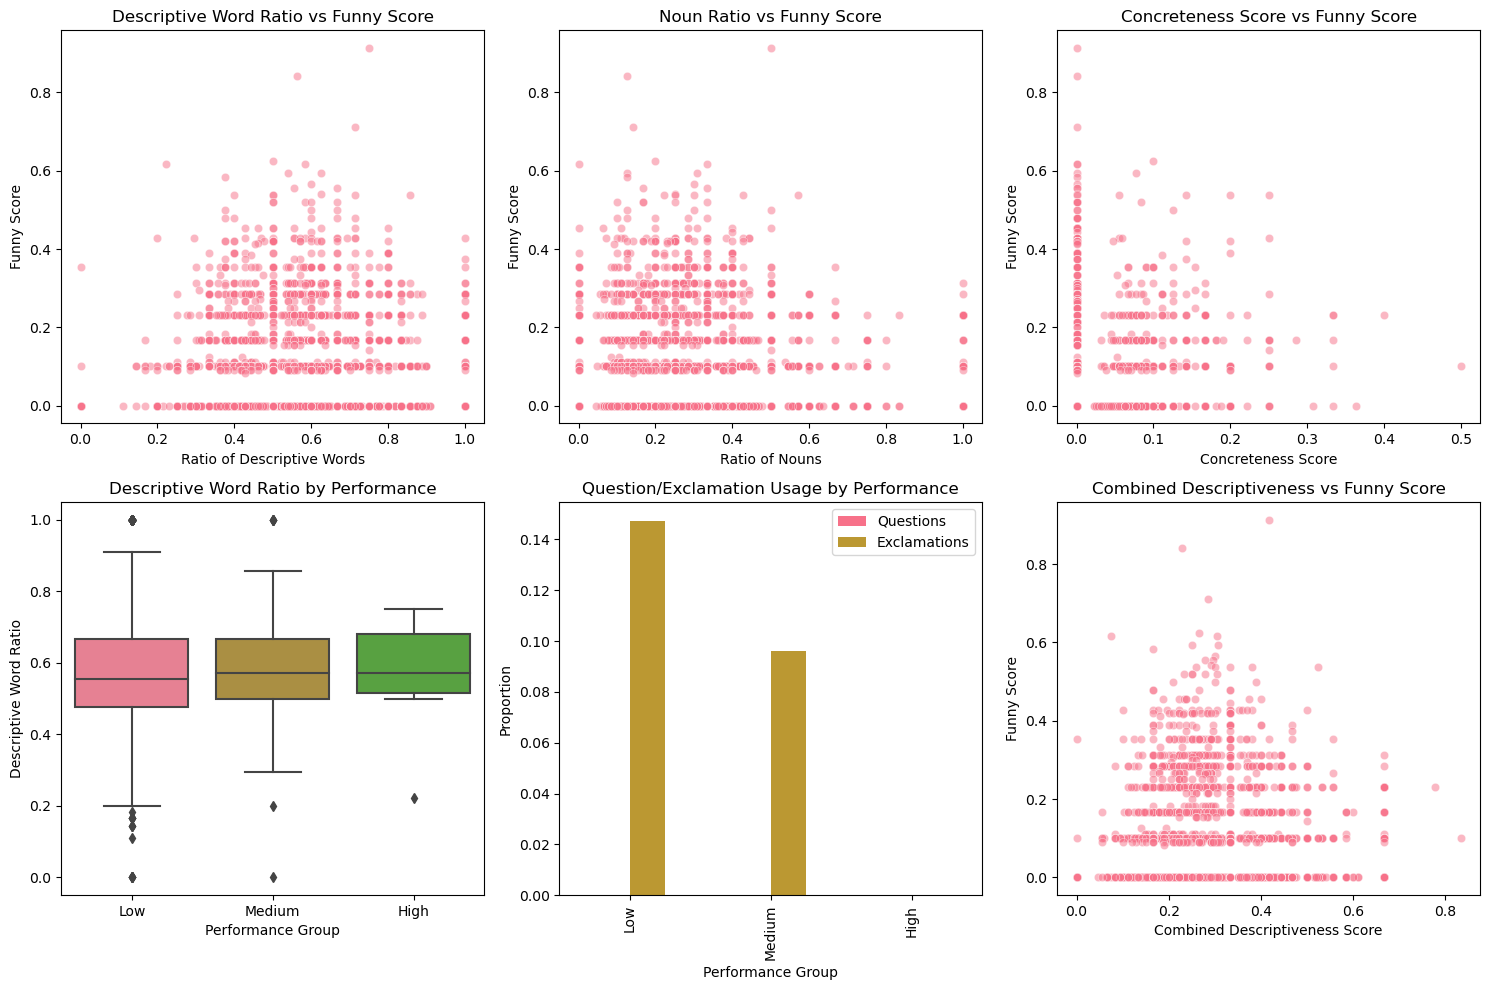

In [44]:
print("=== VISUALIZING DESCRIPTIVENESS vs SUCCESS ===")

plt.figure(figsize=(15, 10))

# Plot 1: Descriptive word ratio vs success
plt.subplot(2, 3, 1)
sns.scatterplot(data=df, x='descriptive_word_ratio', y='success_metric', alpha=0.5)
plt.title('Descriptive Word Ratio vs Funny Score')
plt.xlabel('Ratio of Descriptive Words')
plt.ylabel('Funny Score')

# Plot 2: Noun ratio vs success
plt.subplot(2, 3, 2)
sns.scatterplot(data=df, x='noun_ratio', y='success_metric', alpha=0.5)
plt.title('Noun Ratio vs Funny Score')
plt.xlabel('Ratio of Nouns')
plt.ylabel('Funny Score')

# Plot 3: Concreteness vs success
plt.subplot(2, 3, 3)
sns.scatterplot(data=df, x='concreteness_score', y='success_metric', alpha=0.5)
plt.title('Concreteness Score vs Funny Score')
plt.xlabel('Concreteness Score')
plt.ylabel('Funny Score')

# Plot 4: Box plots by performance group
plt.subplot(2, 3, 4)
sns.boxplot(data=df, x='performance_group', y='descriptive_word_ratio')
plt.title('Descriptive Word Ratio by Performance')
plt.xlabel('Performance Group')
plt.ylabel('Descriptive Word Ratio')

# Plot 5: Question/Exclamation usage
plt.subplot(2, 3, 5)
question_data = df.groupby('performance_group')['question_indicator'].mean()
exclamation_data = df.groupby('performance_group')['exclamation_indicator'].mean()

pd.DataFrame({
    'Questions': question_data,
    'Exclamations': exclamation_data
}).plot(kind='bar', ax=plt.gca())
plt.title('Question/Exclamation Usage by Performance')
plt.xlabel('Performance Group')
plt.ylabel('Proportion')
plt.legend()

# Plot 6: Combined descriptiveness score
plt.subplot(2, 3, 6)
# Create a combined descriptiveness score
df['combined_descriptiveness'] = (df['descriptive_word_ratio'] + df['noun_ratio'] + df['concreteness_score']) / 3
sns.scatterplot(data=df, x='combined_descriptiveness', y='success_metric', alpha=0.5)
plt.title('Combined Descriptiveness vs Funny Score')
plt.xlabel('Combined Descriptiveness Score')
plt.ylabel('Funny Score')

plt.tight_layout()
plt.show()

NOT VERY REPRESENTATIVE -> À CHECK PARCE QUE WTF